# Can Quantum Kernels Improve EEG-Based Mental Workload Classification?

## Introduction

The **STEW (Simultaneous Task EEG Workload) dataset** contains electroencephalography (EEG) recordings from 48 participants under resting and multitasking conditions. The signals were recorded using a 14-channel EEG headset at a sampling rate of 128 Hz. The dataset provides an opportunity to investigate whether brain activity patterns can be used to distinguish between different levels of mental workload.

The objective of this project is to investigate whether **quantum kernels can improve EEG-based mental workload classification compared with classical machine learning approaches**. In particular, we evaluate a Quantum Support Vector Classifier (QSVC), which uses a quantum feature map to represent data in a quantum feature space, and compare it with classical classifiers such as Support Vector Machines (SVM), Logistic Regression, and Random Forest.

We also investigate how feature selection and dimensionality reduction influence classification performance. Specifically, we compare ANOVA-based feature selection and Principal Component Analysis (PCA), examining their impact on both classical and quantum classification. Because quantum kernel methods can be computationally expensive, we also consider the practical limitations imposed by training time and the number of features that can be processed.

Article presenting the dataset and its acquisition methods: [Lim et al., 2018](https://pubmed.ncbi.nlm.nih.gov/30281467/)

Original dataset in EDF format: [STEW: Simultaneous Task EEG Workload Dataset](https://ieee-dataport.org/open-access/stew-simultaneous-task-eeg-workload-dataset)

## Project Workflow

### 1. Data Preprocessing and Feature Extraction

Preprocessed dataset from: [monster-monash/STEW](https://huggingface.co/datasets/monster-monash/STEW)

The first stage consists of preprocessing the EEG recordings and extracting meaningful features. Each sample contains recordings from 14 channels over two seconds, sampled at 128 Hz. This corresponds to 256 data points per channel, or 3,584 raw features per sample ($14 \times 256$).

To obtain a more compact representation, we extract 15 features from each EEG channel, resulting in 210 features per sample ($14 \times 15$). These features describe the signals in both the time and frequency domains. They include statistical measures such as the mean, standard deviation, variance, root mean square (RMS), skewness, and kurtosis, as well as frequency-band power, relative power in the delta, theta, alpha, beta, and gamma bands, and spectral entropy.

The resulting feature matrix serves as the input for the subsequent classification experiments. This representation also provides a basis for investigating whether reducing the number of features can make quantum kernel methods more computationally feasible.

### 2. Feature Selection and Dimensionality Reduction

The second stage investigates two techniques for reducing the number of input features: **ANOVA-based feature selection** and **Principal Component Analysis (PCA)**.

ANOVA selects features according to their statistical relationship with the target classes, retaining those that show the strongest discriminatory potential. PCA, in contrast, transforms the original features into a smaller set of components that capture as much variance in the data as possible.

We evaluate these methods in combination with classical classifiers and, where computationally feasible, the quantum classifier. This allows us to examine not only their influence on predictive performance but also their role in reducing the computational burden of quantum kernel evaluation.

### 3. Classical and Quantum Classification

We compare several classical classification models, including SVM, Logistic Regression, and Random Forest, with a Quantum Support Vector Classifier (QSVC) based on a quantum kernel.

The quantum kernel uses a quantum feature map to encode classical input data into quantum states. Similarities between encoded samples are then used to construct a kernel matrix for classification. In our experiments, the Z feature map is used to explore whether this quantum representation can capture patterns that are useful for distinguishing mental workload levels.

For the classical models, we evaluate different combinations of feature selection or dimensionality reduction methods and classifiers. For the QSVC, we investigate a more limited range of feature dimensions because quantum kernel computation requires substantially more computational resources in our experimental environment.

### 4. Model Selection and Evaluation

We use a training and testing strategy that accounts for the grouping of samples by participant. Stratified group cross-validation is used during model selection to preserve class proportions as much as possible while ensuring that samples from the same participant do not appear in both the training and validation folds.

For the classical pipelines, GridSearchCV evaluates the selected hyperparameter combinations using weighted F1-score as the primary selection metric. The quantum experiments focus on the configurations that can be evaluated within reasonable computational limits.

We assess classification performance using complementary metrics, including weighted F1-score, precision, recall, and accuracy. Confusion matrices provide further insight into the types of classification errors made by each model. Precision–recall and ROC curves are also used where appropriate to compare the models across different decision thresholds.

In addition to predictive performance, we consider computational cost, particularly the training time required by the quantum approach. This is essential for interpreting the results fairly, since a model that achieves competitive performance but requires substantially more computation may be less practical under current constraints.

### 5. Comparative Analysis and Discussion

Finally, we compare the classical and quantum approaches to determine whether quantum kernels provide a measurable advantage for EEG-based mental workload classification under our experimental conditions.

The analysis considers the influence of feature selection, dimensionality reduction, classifier choice, and computational limitations on the observed results. Particular attention is given to the difference between the dimensionalities explored by the classical models and the smaller feature spaces accessible to the QSVC within the available computational budget.

Rather than assuming that quantum classification must outperform classical methods, this project aims to establish what can be concluded from the experiments, identify their limitations, and discuss the potential of quantum kernels for future EEG classification research.

# Project

In [1]:
import os
import time

from huggingface_hub import hf_hub_download

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import welch
from scipy.stats import skew, kurtosis

from sklearn.base import clone

from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.decomposition import PCA

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    f1_score,
    confusion_matrix
)
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
)

from concurrent.futures import ThreadPoolExecutor
import threading

from time import perf_counter

## Preprocessing
### Data Loading

Preprocessed dataset from: [monster-monash/STEW](https://huggingface.co/datasets/monster-monash/STEW)

In [2]:
REPO_ID = "monster-monash/STEW"

def download_file(filename):
    return hf_hub_download(repo_id=REPO_ID,filename=filename,repo_type="dataset")

X_path = download_file("STEW_X.npy")

Y_path = download_file("STEW_y.csv")

SUBJECT_ID_path = download_file("STEW_subject_id.csv")

X = np.load(X_path)
Y = pd.read_csv(Y_path, header= None).squeeze().to_numpy()
SUBJECT_ID = pd.read_csv(SUBJECT_ID_path, header=None).squeeze().to_numpy()

In [3]:
EEG_CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1", "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]

SAMPLING_FREQUENCY = 128

FREQUENCY_BANDS = {
    "delta": (1, 4),
    "theta": (4, 8),
    "alpha": (8, 12),
    "beta": (12, 30),
    "gamma": (30, 50),
}

In [4]:
# We verify the shapes of the three arrays

assert(X.ndim == 3)
assert(X.shape == (28512,14,256)) # Expected shape from the tabular dataset description
assert(len(X)==len(Y)==len(SUBJECT_ID))

### Data Cleaning

We remove all the data from subjects 5, 24, 42, as the dataset presentation article (Lim et al, 2018) states that ratings were not obtained for this subjects.

In [5]:
SUBJECTS_TO_REMOVE=[5,24,42]

mask=np.logical_not(np.isin(SUBJECT_ID,SUBJECTS_TO_REMOVE))
X=X[mask]
Y=Y[mask]
SUBJECT_ID=SUBJECT_ID[mask]

In [6]:
#We test that the removal was successful
for subject in SUBJECTS_TO_REMOVE:
    assert(X[SUBJECT_ID==subject].size==0)
    assert(Y[SUBJECT_ID==subject].size==0)
    assert(SUBJECT_ID[SUBJECT_ID==subject].size==0)

    assert(X[SUBJECT_ID==(subject-1)].size!=0)
    assert(Y[SUBJECT_ID==(subject-1)].size!=0)
    assert(SUBJECT_ID[SUBJECT_ID==(subject-1)].size!=0)


assert(X.shape == (28512-28512*3/48,14,256)) # Expected new shape, given that we removed 3/48th of the data.
assert(len(X)==len(Y)==len(SUBJECT_ID))

### Data Exploration

In [7]:
def explore_stew(X, y, subject_ids, sampling_rate):
    X = np.asarray(X)
    y = np.asarray(y).ravel()
    subject_ids = np.asarray(subject_ids).ravel()

    n_epochs, n_channels, n_times = X.shape

    # 1. Overall dataset summary
    summary = pd.DataFrame({
        "Metric": [
            "Number of epochs",
            "Number of channels",
            "Time points per epoch",
            "Sampling rate (Hz)",
            "Duration per epoch (s)",
            "Number of subjects",
            "Number of classes",
            "NaN values",
            "Infinite values",
            "Constant epoch-channel signals"
        ],
        "Value": [
            n_epochs,
            n_channels,
            n_times,
            sampling_rate,
            round(n_times / sampling_rate, 3),
            pd.Series(subject_ids).nunique(),
            pd.Series(y).nunique(),
            int(np.isnan(X).sum()),
            int(np.isinf(X).sum()),
            int((np.nanstd(
                np.where(np.isfinite(X), X, np.nan), axis=2
            ) == 0).sum())
        ]
    })

    # 2. Overall class distribution
    class_counts = (
        pd.Series(y, name="Class")
        .value_counts(dropna=False)
        .rename_axis("Class")
        .reset_index(name="Epoch count")
    )
    class_counts["Percentage (%)"] = (
        100 * class_counts["Epoch count"] / n_epochs
    ).round(2)

    # 3. Epoch count per subject
    subject_counts = (
        pd.DataFrame({"Subject": subject_ids})
        .groupby("Subject", dropna=False)
        .size()
        .reset_index(name="Epoch count")
        .sort_values("Subject")
        .reset_index(drop=True)
    )

    # 4. Class distribution per subject
    subject_class_counts = pd.crosstab(
        pd.Series(subject_ids, name="Subject"),
        pd.Series(y, name="Class"),
        dropna=False
    ).reset_index()

    # 5. Basic signal statistics
    finite_X = np.where(np.isfinite(X), X, np.nan)

    signal_summary = pd.DataFrame({
        "Statistic": [
            "Minimum",
            "Maximum",
            "Mean",
            "Standard deviation",
            "Median absolute amplitude"
        ],
        "Value": [
            np.nanmin(finite_X) if np.isfinite(finite_X).any() else np.nan,
            np.nanmax(finite_X) if np.isfinite(finite_X).any() else np.nan,
            np.nanmean(finite_X),
            np.nanstd(finite_X),
            np.nanmedian(np.abs(finite_X))
        ]
    })

    return {
    "dataset_summary": summary,
    "class_counts": class_counts,
    "subject_counts": subject_counts,
    "subject_class_counts": subject_class_counts,
    "signal_summary": signal_summary
    }

In [8]:
reports = explore_stew(X, Y, SUBJECT_ID, SAMPLING_FREQUENCY)

display(reports["dataset_summary"])
display(reports["class_counts"])
display(reports["subject_counts"])
display(reports["subject_class_counts"])
display(reports["signal_summary"])

,Metric,Value
0,Number of epochs,26730.0
1,Number of channels,14.0
2,Time points per epoch,256.0
3,Sampling rate (Hz),128.0
4,Duration per epoch (s),2.0
5,Number of subjects,45.0
6,Number of classes,2.0
7,NaN values,0.0
8,Infinite values,0.0
9,Constant epoch-channel signals,0.0


,Class,Epoch count,Percentage (%)
0,1,13365,50.0
1,0,13365,50.0


,Subject,Epoch count
0,1,594
1,2,594
2,3,594
3,4,594
4,6,594
5,7,594
6,8,594
7,9,594
8,10,594
9,11,594


Class,Subject,0,1
0,1,297,297
1,2,297,297
2,3,297,297
3,4,297,297
4,6,297,297
5,7,297,297
6,8,297,297
7,9,297,297
8,10,297,297
9,11,297,297


,Statistic,Value
0,Minimum,-7131.082031
1,Maximum,7054.263672
2,Mean,0.431821
3,Standard deviation,95.316826
4,Median absolute amplitude,11.135169


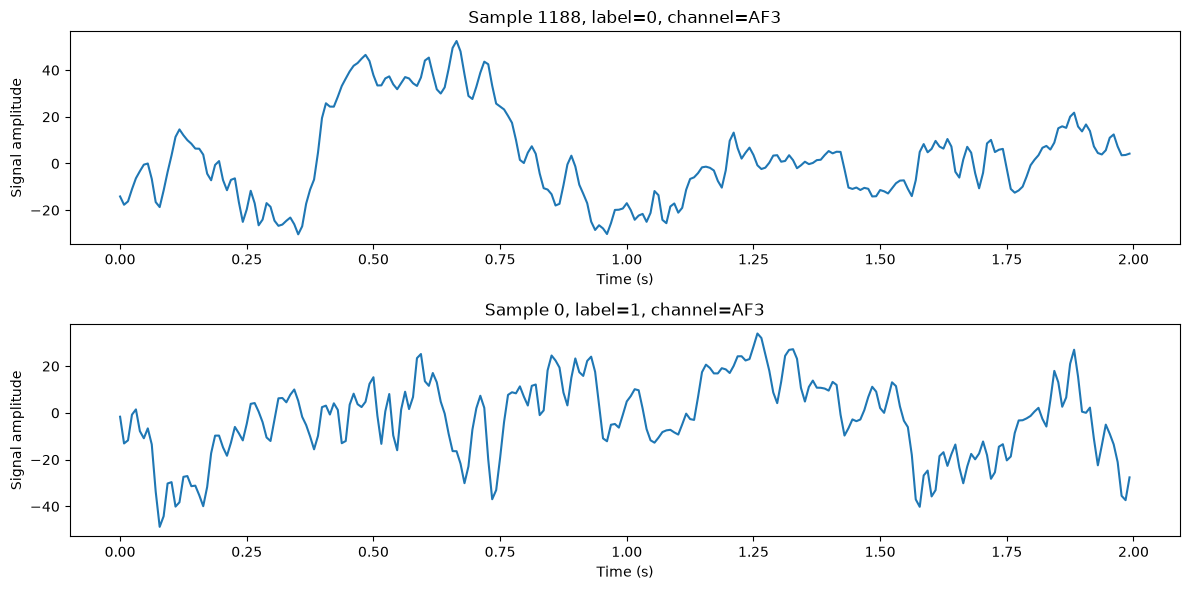

In [9]:
sample_indices = [
    np.flatnonzero(Y == label)[0]
    for label in np.unique(Y)
]

timeX = np.arange(X.shape[2]) / SAMPLING_FREQUENCY

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

for ax, idx in zip(axes, sample_indices):
    ax.plot(timeX, X[idx, 0, :])
    ax.set_title(f"Sample {idx}, label={Y[idx]}, channel={EEG_CHANNELS[0]}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Signal amplitude")

plt.tight_layout()
plt.show()

### Feature engineering

We crete a .csv table with the chosen features:

In [10]:
def extract_features(signal):

    # Time-domain features
    new_features = {
        "mean": np.mean(signal),
        "std" : np.std(signal),
        "var" : np.var(signal),
        "rms" : np.sqrt(np.mean(signal**2)),
        "skewness": skew(signal, bias=True),
        "kurtosis": kurtosis(signal, fisher=True, bias=True),
    }
    
    # Frequency-domain features
    freqs, psd = welch(
        signal,
        fs=SAMPLING_FREQUENCY,
        nperseg=len(signal)
    )

    frequency_resolution = freqs[1] - freqs[0] 

    total_mask = (freqs >= 1) & (freqs < 45)
    total_power = np.sum(psd[total_mask]) * frequency_resolution

    for band, (low, high) in FREQUENCY_BANDS.items():

        mask = (freqs >= low) & (freqs < high)

        power = (
            np.sum(psd[mask]) * frequency_resolution
            if np.any(mask) else 0.0
        )

        new_features[f"{band}_power"] = power

        new_features[f"{band}_relative_power"] = (
            power / total_power
            if total_power > 1e-12 else 0.0
        )

    # Spectral entropy over the 1–45 Hz range
    psd_band = psd[total_mask]
    power_sum = psd_band.sum()

    if power_sum > 1e-12:
        probabilities = psd_band / power_sum
        probabilities = probabilities[probabilities > 0]

        new_features["spectral_entropy"] = -np.sum(
            probabilities * np.log2(probabilities)
        )
    else:
        new_features["spectral_entropy"] = 0.0

    return new_features

In [11]:
def create_dataset():
    records = []

    for sample_idx in range(len(X)):

        eeg_sample = X[sample_idx]

        record = {
            "sample_id": sample_idx,
            "subject_id": SUBJECT_ID[sample_idx],
        }

        for channel_idx, channel_name in enumerate(EEG_CHANNELS):

            signal = eeg_sample[channel_idx, :]

            channel_features = extract_features(signal)

            for feature_name, value in channel_features.items():
                column_name = f"{channel_name}_{feature_name}"
                record[column_name] = value

        record["label"] = Y[sample_idx]
        records.append(record)

        if (sample_idx + 1) % 1000 == 0:
            print(f"Processed {sample_idx + 1}/{len(X)} examples")

    print(f"Processed {sample_idx + 1}/{len(X)} examples")
    return records

We create a dataframe with the extracted outputs and write it to a .csv file.

In [12]:
DATASET_PATH = "STEW_features.csv"

if(os.path.isfile(DATASET_PATH)):
    DATASET_EXT=pd.read_csv(DATASET_PATH)
else:
    new_dataset=create_dataset()
    DATASET_EXT = pd.DataFrame(new_dataset)
    DATASET_EXT.to_csv(DATASET_PATH, index=False)
    
print(DATASET_EXT.shape)

(26730, 241)


In [13]:
print(DATASET_EXT.head())
print(DATASET_EXT.shape)

   sample_id  subject_id  AF3_mean    AF3_std    AF3_var    AF3_rms  \
0          0          12 -2.364527  16.718996  279.52484  16.885374   
1          1          12  1.513650  15.534682  241.32635  15.608251   
2          2          12  0.492984  14.909048  222.27971  14.917197   
3          3          12 -2.007783  14.349675  205.91318  14.489458   
4          4          12  1.876135  13.039218  170.02121  13.173500   

   AF3_skewness  AF3_kurtosis  AF3_delta_power  AF3_delta_relative_power  ...  \
0     -0.339354     -0.337851       114.806351                  0.573799  ...   
1     -0.468445     -0.308483       185.131073                  0.716253  ...   
2     -0.283593     -0.254668       141.955475                  0.627093  ...   
3     -0.157667     -0.236524        81.054817                  0.508537  ...   
4     -0.063752     -0.338315        59.304790                  0.397247  ...   

   AF4_theta_power  AF4_theta_relative_power  AF4_alpha_power  \
0       323.099518   

In [14]:
X_ = DATASET_EXT.drop(columns=['sample_id', 'subject_id', 'label'])
y_ = DATASET_EXT['label']
subjects = DATASET_EXT['subject_id']

### Visualisation of the results

/home/maxence/Desktop/university/fourth-year/hoai/.venv/lib/python3.14/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/maxence/Desktop/university/fourth-year/hoai/.venv/lib/python3.14/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


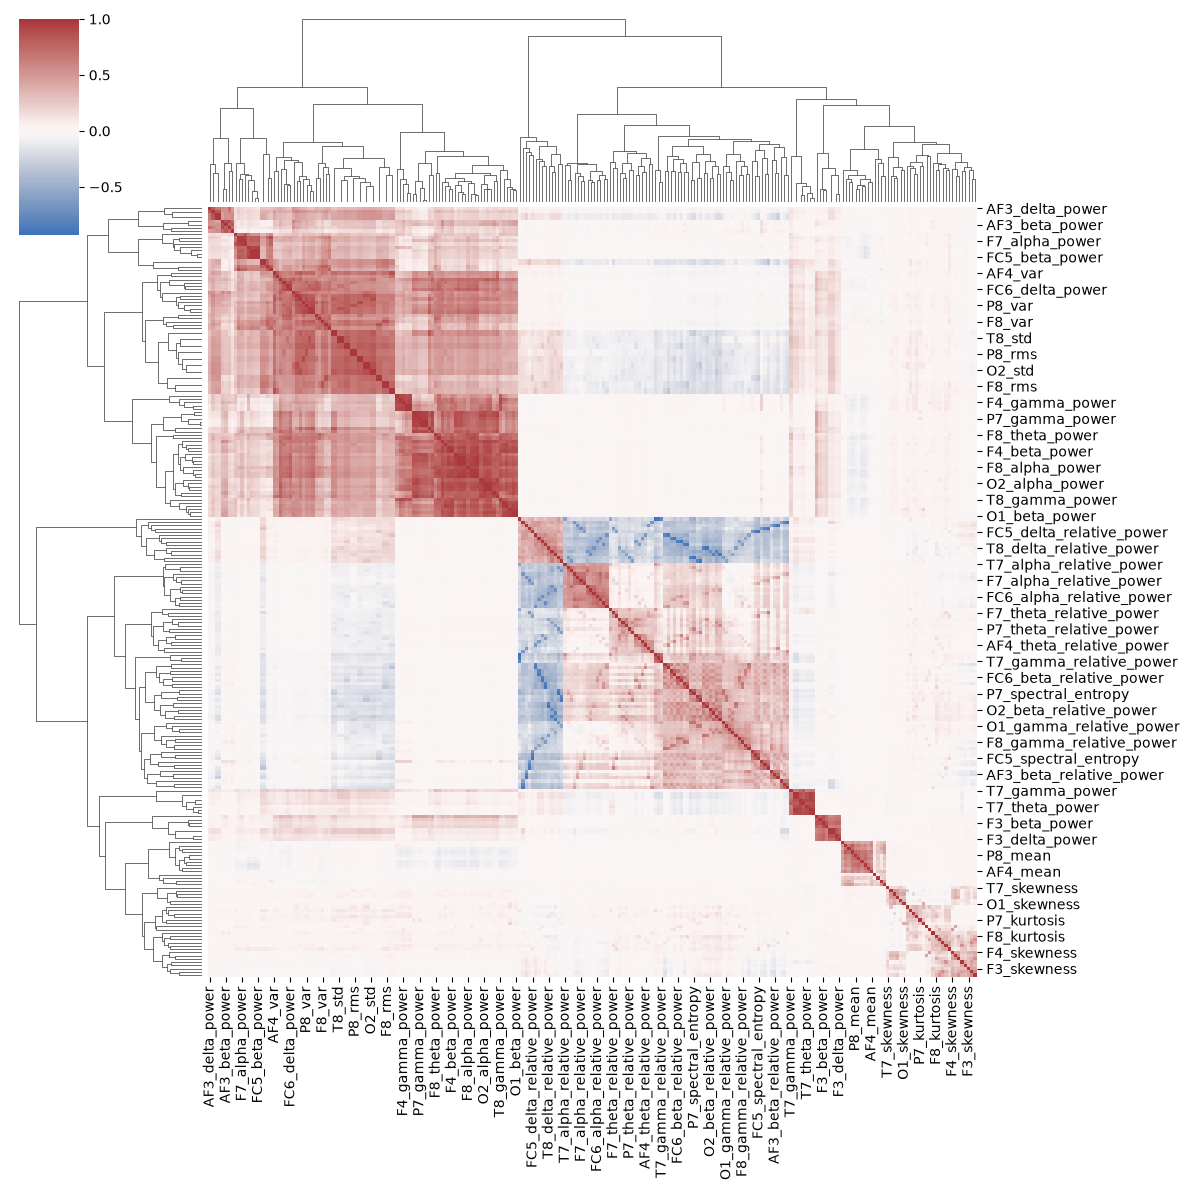

In [15]:
sns.clustermap(
    X_.corr(),
    cmap="vlag",
    center=0,
    figsize=(12, 12)
)
plt.show()

## Model Training

### Pipelines: Features reduction and Model training

We want to analyze the impact of PCA and ANOVA on different SVM models like RBF and Logistic Regression as a guideline.

#### Hyperparameters

In [16]:
# Fixed seed so that all results are reproducible
RANDOM_STATE = 42

# Feature subset sizes to compare (the smallest ones go to the quantum SVM)
CANDIDATE_KS = [10, 20, 50, 100, 150]

# Main metric used to compare the methods
SCORING = 'f1_weighted'

#### Train Test Split

In [17]:
UNIQUE_SUBJECTS = np.unique(subjects)

SUB_train, SUB_test = train_test_split(
    UNIQUE_SUBJECTS,
    test_size=0.25,
    random_state=RANDOM_STATE
)

print(SUB_train.shape)
print(SUB_test.shape)

# Train matrix
train=np.isin(subjects, SUB_train)
X_train=X_[train]
y_train=y_[train]
subjects_train = subjects[train]

print(X_train.shape)
print(y_train.shape)

# Test matrix
test=np.isin(subjects, SUB_test)
X_test=X_[test]
y_test=y_[test]
subjects_test = subjects[test]

print(X_test.shape)
print(y_test.shape)

# Make sure the data is clean before any modelling
assert X_.isna().sum().sum() == 0, "NaN values found in features"
assert all(np.issubdtype(t, np.number) for t in X_.dtypes), "Non-numeric columns found"

# Grouped, stratified CV: no subject appears in both train and validation folds.
# The same object is used for both methods, so they see identical splits.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

(33,)
(12,)
(19602, 238)
(19602,)
(7128, 238)
(7128,)


#### Pipelines

In [18]:
# All reducers
reducers = {
    "ANOVA": (
        SelectKBest(score_func=f_classif),
        {"reducer__k": CANDIDATE_KS},
    ),
    "PCA": (
        PCA(),
        {"reducer__n_components": CANDIDATE_KS},
    ),
    "None": (
        "passthrough",
        {},
    ),
}

In [19]:
# All classifiers
classifiers = {
    "SVC": (
        SVC(),
        {
            "classifier__kernel": ["rbf"],
            "classifier__C": [0.1, 1, 10, 100],
            #"classifier__gamma": ["scale", 0.01, 0.1, 1],
        },
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {
            "classifier__C": [0.1, 1, 10, 100],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=1),
        {
            "classifier__n_estimators": [100, 300],
            "classifier__max_depth": [None, 20],
        },
    ),    
}

In [20]:
searches = {}
results = []

for reducer_name, (reducer, reducer_grid) in reducers.items():
    for classifier_name, (classifier, classifier_grid) in classifiers.items():
        t0 =  time.time()
        
        name = f"{reducer_name} + {classifier_name}"

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("reducer", reducer),
            ("classifier", classifier),
        ])

        param_grid = {
            **reducer_grid,
            **classifier_grid,
        }

        print(f"\nExecuting GridSearchCV: {name}")

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            cv=cv,
            scoring=SCORING,
            n_jobs=-1,
            verbose=1,
        )

        search.fit(X_train, y_train, groups=subjects_train)

        searches[name] = search

        results.append({
            "Model": name,
            "Best CV F1-weighted": search.best_score_,
            "Best parameters": search.best_params_,
        })

        print(f"- Best score: {search.best_score_:.4f}")
        print(f"- Best parameters: {search.best_params_}")

        print(f"Time required: {time.time() - t0}")


Executing GridSearchCV: ANOVA + SVC
Fitting 5 folds for each of 20 candidates, totalling 100 fits
- Best score: 0.7138
- Best parameters: {'classifier__C': 0.1, 'classifier__kernel': 'rbf', 'reducer__k': 100}
Time required: 95.07546901702881

Executing GridSearchCV: ANOVA + Logistic Regression
Fitting 5 folds for each of 20 candidates, totalling 100 fits
- Best score: 0.7225
- Best parameters: {'classifier__C': 0.1, 'reducer__k': 100}
Time required: 6.256171703338623

Executing GridSearchCV: ANOVA + Random Forest
Fitting 5 folds for each of 20 candidates, totalling 100 fits
- Best score: 0.7371
- Best parameters: {'classifier__max_depth': None, 'classifier__n_estimators': 300, 'reducer__k': 150}
Time required: 316.3401219844818

Executing GridSearchCV: PCA + SVC
Fitting 5 folds for each of 20 candidates, totalling 100 fits
- Best score: 0.7107
- Best parameters: {'classifier__C': 0.1, 'classifier__kernel': 'rbf', 'reducer__n_components': 150}
Time required: 92.42313766479492

Executin

### Results

#### Scores table

In [21]:
comparison_results = []

for name, search in searches.items():
    print(name)
    cv_results = pd.DataFrame(search.cv_results_)

    # Identify the dimensionality parameter, if available
    if (
        "param_reducer__k" in cv_results.columns
        and cv_results["param_reducer__k"].notna().any()
    ):
        dim_param = "param_reducer__k"

    elif (
        "param_reducer__n_components" in cv_results.columns
        and cv_results["param_reducer__n_components"].notna().any()
    ):
        dim_param = "param_reducer__n_components"

    else:
        dim_param = None

    # Reducer with a dimensionality parameter (ANOVA / PCA)
    if dim_param is not None:

        best_by_dim = (
            cv_results
            .dropna(subset=[dim_param, "mean_test_score"])
            .loc[
                lambda df: df.groupby(dim_param)["mean_test_score"].idxmax()
            ]
            .sort_values(dim_param)
        )

    # No reducer (None)
    else:
        best_idx = cv_results["mean_test_score"].idxmax()
        best_by_dim = cv_results.loc[[best_idx]]

    # Store the results
    for _, row in best_by_dim.iterrows():
        comparison_results.append({
            "Model": name,
            "k": row[dim_param] if dim_param is not None else X_.shape[1],
            "F1_mean": row["mean_test_score"],
            "F1_std": row["std_test_score"],
            "params": row["params"],
        })


# Build the results DataFrame
results_df = pd.DataFrame(comparison_results)

# Preserve None instead of letting pandas convert it to NaN
results_df["k"] = pd.Series(
    [result["k"] for result in comparison_results],
    dtype=object,
)

results_df = (
    results_df
    .sort_values(["Model", "k"], na_position="first")
    .reset_index(drop=True)
)

results_df.to_csv(
    "all_models_f1_by_dimension.csv",
    index=False,
    na_rep="None",
)

# Keep the best result for each model
if not results_df.empty:
    best_results_df = (
        results_df.loc[
            results_df.groupby("Model")["F1_mean"].idxmax()
        ]
        .sort_values("F1_mean", ascending=False)
        .reset_index(drop=True)
    )

    best_results_df.to_csv(
        "best_results_by_model.csv",
        index=False,
        na_rep="None",
    )

    display(results_df)
    display(best_results_df)
else:
    print("No results available.")

ANOVA + SVC
ANOVA + Logistic Regression
ANOVA + Random Forest
PCA + SVC
PCA + Logistic Regression
PCA + Random Forest
None + SVC
None + Logistic Regression
None + Random Forest


,Model,k,F1_mean,F1_std,params
0,ANOVA + Logistic Regression,10,0.668081,0.036346,"{'classifier__C': 100, 'reducer__k': 10}"
1,ANOVA + Logistic Regression,20,0.685847,0.012093,"{'classifier__C': 0.1, 'reducer__k': 20}"
2,ANOVA + Logistic Regression,50,0.706042,0.024813,"{'classifier__C': 1, 'reducer__k': 50}"
3,ANOVA + Logistic Regression,100,0.722477,0.018471,"{'classifier__C': 0.1, 'reducer__k': 100}"
4,ANOVA + Logistic Regression,150,0.709616,0.005641,"{'classifier__C': 0.1, 'reducer__k': 150}"
5,ANOVA + Random Forest,10,0.653650,0.029489,"{'classifier__max_depth': 20, 'classifier__n_e..."
6,ANOVA + Random Forest,20,0.683831,0.023519,"{'classifier__max_depth': 20, 'classifier__n_e..."
7,ANOVA + Random Forest,50,0.721925,0.023464,"{'classifier__max_depth': None, 'classifier__n..."
8,ANOVA + Random Forest,100,0.714326,0.040684,"{'classifier__max_depth': None, 'classifier__n..."
9,ANOVA + Random Forest,150,0.737085,0.033323,"{'classifier__max_depth': None, 'classifier__n..."


,Model,k,F1_mean,F1_std,params
0,None + Random Forest,238,0.747459,0.034853,"{'classifier__max_depth': None, 'classifier__n..."
1,ANOVA + Random Forest,150,0.737085,0.033323,"{'classifier__max_depth': None, 'classifier__n..."
2,ANOVA + Logistic Regression,100,0.722477,0.018471,"{'classifier__C': 0.1, 'reducer__k': 100}"
3,None + Logistic Regression,238,0.718970,0.014784,{'classifier__C': 0.1}
4,PCA + Logistic Regression,150,0.715989,0.016931,"{'classifier__C': 0.1, 'reducer__n_components'..."
5,ANOVA + SVC,100,0.713774,0.013903,"{'classifier__C': 0.1, 'classifier__kernel': '..."
6,PCA + SVC,150,0.710670,0.012972,"{'classifier__C': 0.1, 'classifier__kernel': '..."
7,None + SVC,238,0.710570,0.013743,"{'classifier__C': 0.1, 'classifier__kernel': '..."
8,PCA + Random Forest,100,0.691846,0.023723,"{'classifier__max_depth': None, 'classifier__n..."


#### Plotting

In [22]:
def reducer_plot(ax):
    for classifier_name in classifier_names:
        model_name = f"{reducer_name} + {classifier_name}"

        model_results = (
            results_df[results_df["Model"] == model_name]
            .sort_values("k")
        )

        if model_results.empty:
            continue

        means = model_results["F1_mean"]
        stds = model_results["F1_std"]

        ax.errorbar(
            model_results["k"],
            means,
            yerr=stds,
            marker="o",
            color=colors[classifier_name],
            linewidth=2,
            capsize=4,
            label=classifier_name,
        )

    ax.legend(title="Classifier")

In [23]:
def no_reducer_plot(ax):
    labels = []
    means = []
    stds = []
    bar_colors = []

    for classifier_name in classifier_names:
        model_name = f"{reducer_name} + {classifier_name}"

        model_results = results_df[
            results_df["Model"] == model_name
        ]

        if model_results.empty:
            continue

        # Keep the best configuration for this classifier
        best_row = model_results.loc[
            model_results["F1_mean"].idxmax()
        ]

        labels.append(classifier_name)
        means.append(best_row["F1_mean"])
        stds.append(best_row["F1_std"])
        bar_colors.append(colors[classifier_name])

    ax.bar(
        labels,
        means,
        yerr=stds,
        color=bar_colors,
        capsize=4,
        alpha=0.85,
    )

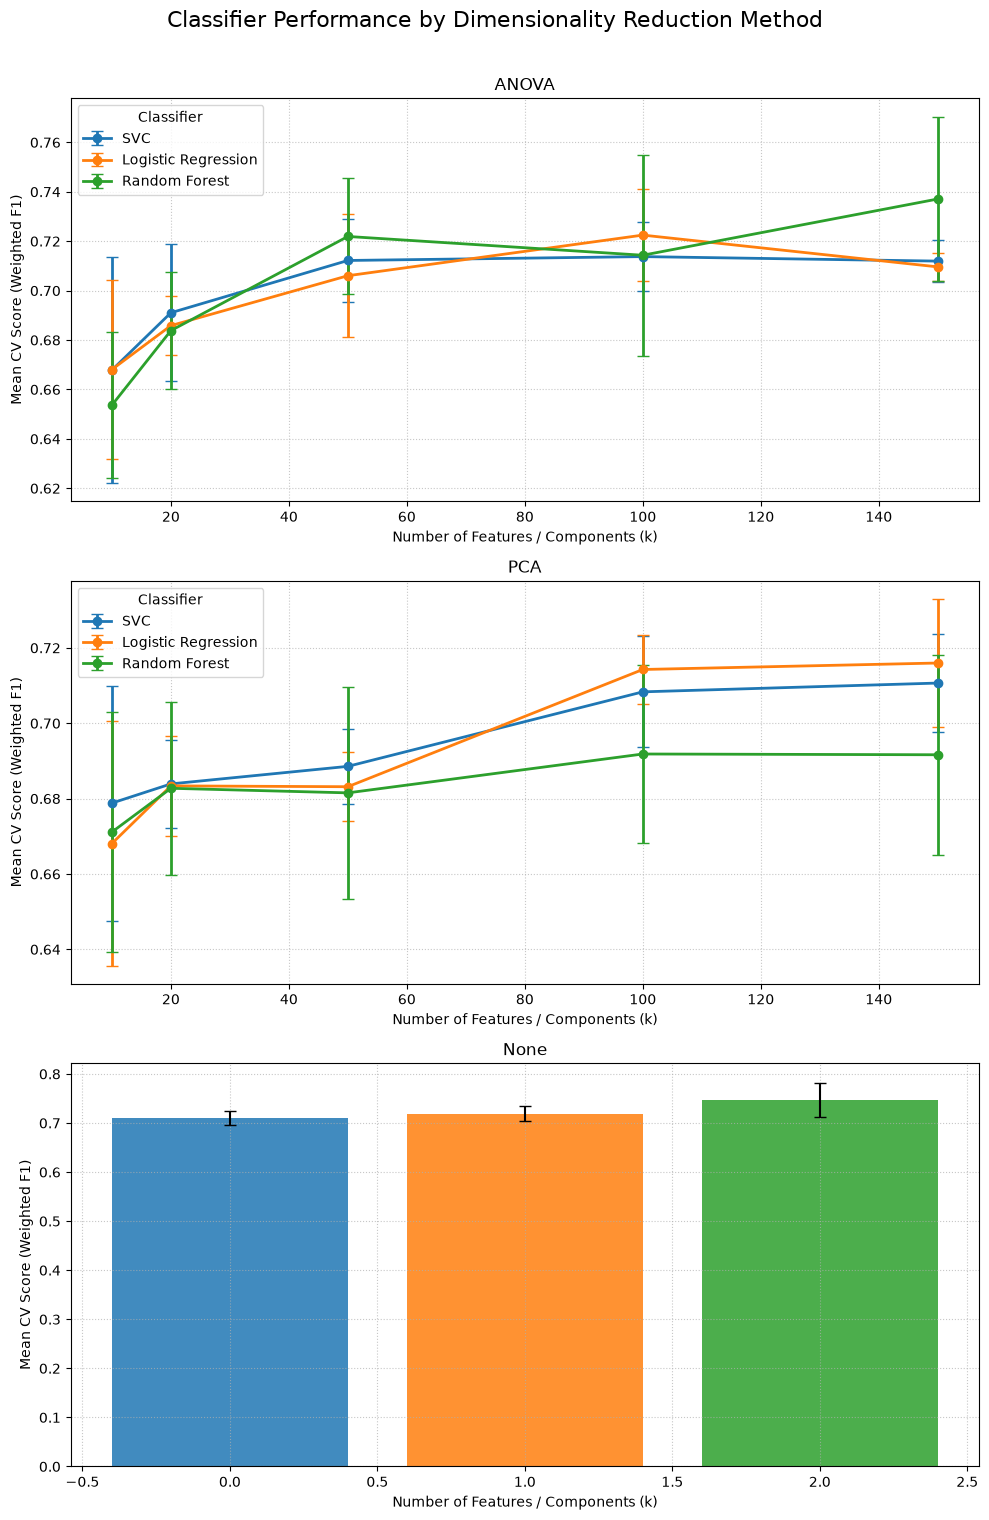

In [24]:
reducer_names = list(reducers.keys())
classifier_names = list(classifiers.keys())

# Generates as many colors as needed
cmap = plt.get_cmap("tab10")
colors = {
    name: cmap(i % cmap.N)
    for i, name in enumerate(classifier_names)
}

fig, axes = plt.subplots(
    nrows=len(reducer_names),
    ncols=1,
    figsize=(10, 5 * len(reducer_names)),
    sharex=False,
    squeeze=False,
)

for row, reducer_name in enumerate(reducer_names):

    ax = axes[row, 0]

    if reducer_name == "None":
        no_reducer_plot(ax) 
    else:
        reducer_plot(ax)

    ax.set_xscale("linear")
    ax.set_title(reducer_name)
    ax.set_xlabel("Number of Features / Components (k)")
    ax.set_ylabel("Mean CV Score (Weighted F1)")
    ax.grid(True, linestyle=":", alpha=0.7)

fig.suptitle(
    "Classifier Performance by Dimensionality Reduction Method",
    fontsize=16,
    y=1.01,
)

plt.tight_layout()

plt.savefig(
    "classifier_comparison_by_reducer.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## Analysis
### Best of each model

In [25]:
# Get the best model for each classifier
best_by_classifier = {}

for key, val in searches.items():
    classifier_name = key.split(" + ")[-1]

    # Keep the best reducer + hyperparameters for this classifier
    if (
        classifier_name not in best_by_classifier
        or val.best_score_ > best_by_classifier[classifier_name]["cv_score"]
    ):
        best_by_classifier[classifier_name] = {
            "pipeline_name": key,
            "estimator": val.best_estimator_,
            "cv_score": val.best_score_,
            "params": val.best_params_,
        }

# Display the best pipeline for each classifier
for classifier_name, result in best_by_classifier.items():
    print(f"\n{classifier_name}")
    print(f"Pipeline: {result['pipeline_name']}")
    print(f"CV F1-score: {result['cv_score']:.4f}")
    print(f"Best parameters: {result['params']}")


SVC
Pipeline: ANOVA + SVC
CV F1-score: 0.7138
Best parameters: {'classifier__C': 0.1, 'classifier__kernel': 'rbf', 'reducer__k': 100}

Logistic Regression
Pipeline: ANOVA + Logistic Regression
CV F1-score: 0.7225
Best parameters: {'classifier__C': 0.1, 'reducer__k': 100}

Random Forest
Pipeline: None + Random Forest
CV F1-score: 0.7475
Best parameters: {'classifier__max_depth': None, 'classifier__n_estimators': 300}


#### Confusion Matrix

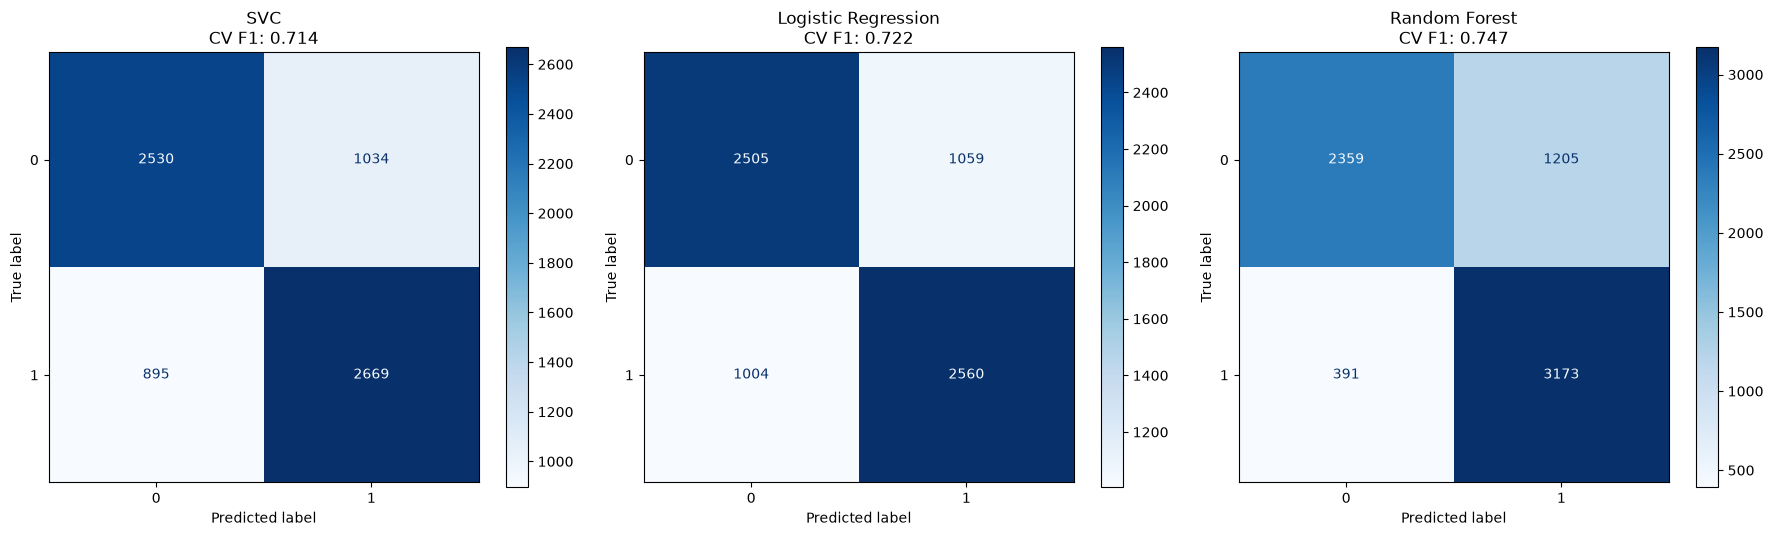

In [27]:
fig, axes = plt.subplots(
    1, len(best_by_classifier),
    figsize=(6 * len(best_by_classifier), 5)
)

for ax, (classifier_name, result) in zip(
    axes, best_by_classifier.items()
):
    model = result["estimator"]
    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        ax=ax,
        cmap="Blues",
        values_format="d",
    )

    ax.set_title(
        f"{classifier_name}\n"
        f"CV F1: {result['cv_score']:.3f}"
    )

plt.tight_layout()
plt.show()

The confusion matrices compare the classification performance of the best pipeline selected for each classifier. Random Forest achieves the best cross-validation F1-score (0.747), followed by Logistic Regression (0.722) and SVC (0.714). On the test set, Random Forest correctly classifies 2,359 samples from class 0 and 3,173 samples from class 1, while misclassifying 1,205 class 0 samples and 391 class 1 samples. This indicates that Random Forest is particularly effective at identifying class 1, but less accurate when identifying class 0. In comparison, SVC and Logistic Regression correctly classify more class 0 samples but produce substantially more false negatives for class 1. Overall, Random Forest provides the best balance for detecting class 1, although its tendency to misclassify class 0 samples highlights a trade-off between the two classes.

#### ROC curve

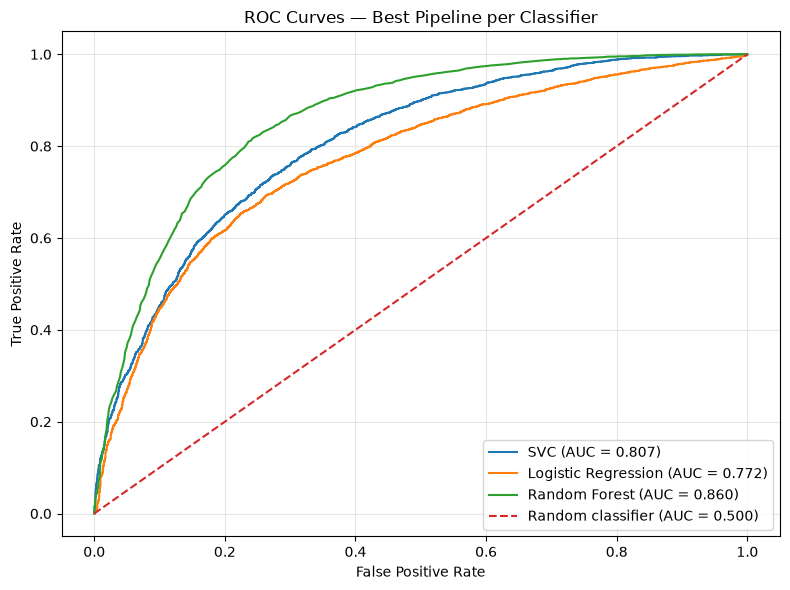

In [28]:
fig, ax = plt.subplots(figsize=(8, 6))

for classifier_name, result in best_by_classifier.items():
    model = result["estimator"]

    # Get the score used to rank positive predictions
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    # Compute ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)

    ax.plot(
        fpr,
        tpr,
        label=f"{classifier_name} (AUC = {roc_auc:.3f})"
    )

# Random classifier baseline
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier (AUC = 0.500)"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — Best Pipeline per Classifier")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The Receiver Operating Characteristic (ROC) curve evaluates the ability of each classifier to distinguish between the two classes across different decision thresholds. The curve plots the true positive rate against the false positive rate, with a curve trying to reach the upper-left corner indicating better discrimination. A model whose ROC curve follows the diagonal line performs approximately at random, whereas a curve that bends towards the upper-left corner indicates stronger predictive performance. The Area Under the Curve (ROC-AUC) summarizes this ability: values closer to 1.0 indicate better class separation, while a value of 0.5 corresponds to random discrimination. In this study, the ROC curves can be used to compare Random Forest, SVC, and Logistic Regression independently of a single classification threshold. If Random Forest achieves the highest ROC-AUC, this would further support its selection as the best-performing classifier. The exact ROC-AUC values should be reported from the computed results rather than inferred from the curve's shape alone.

#### Precision-Recall curve

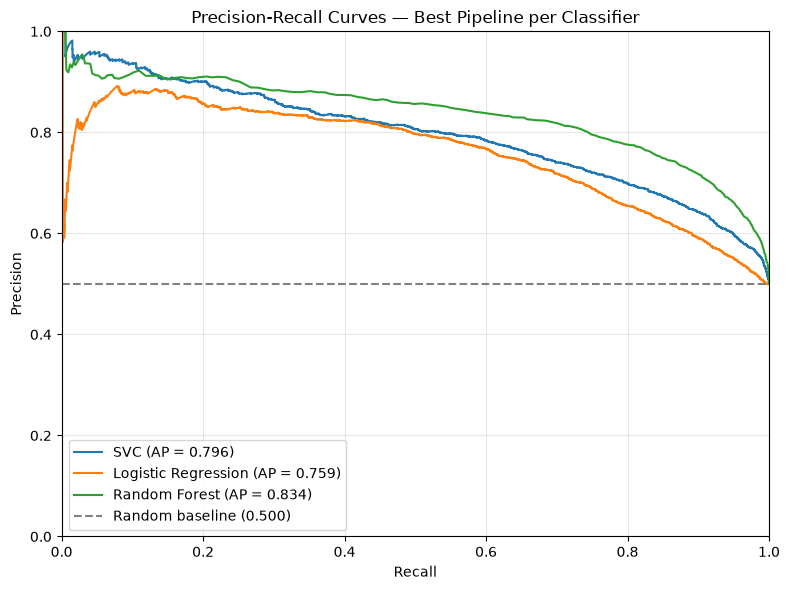

In [29]:
fig, ax = plt.subplots(figsize=(8, 6))

for classifier_name, result in best_by_classifier.items():
    model = result["estimator"]

    # Get the score used to rank positive predictions
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    # Compute Precision-Recall curve
    precision, recall, thresholds = precision_recall_curve(
        y_test,
        y_score,
        pos_label=1,
    )

    # Compute Average Precision
    avg_precision = average_precision_score(
        y_test,
        y_score,
        pos_label=1,
    )

    ax.plot(
        recall,
        precision,
        label=f"{classifier_name} (AP = {avg_precision:.3f})",
    )

# Baseline: proportion of positive samples
positive_ratio = (y_test == 1).mean()

ax.axhline(
    y=positive_ratio,
    linestyle="--",
    color="gray",
    label=f"Random baseline ({positive_ratio:.3f})",
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curves — Best Pipeline per Classifier")
ax.legend(loc="best")
ax.grid(alpha=0.3)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

The precision–recall curves illustrate the trade-off between precision and recall for each classifier across different decision thresholds. Random Forest achieves the highest Average Precision (AP = 0.834), outperforming SVC (AP = 0.796) and Logistic Regression (AP = 0.759). Its curve remains above the other classifiers over most of the recall range, indicating that it generally maintains higher precision while identifying a larger proportion of positive samples. SVC also performs reasonably well, particularly at lower recall levels, whereas Logistic Regression shows lower precision across much of the curve. All three models perform above the random baseline of 0.500, suggesting that they capture meaningful patterns in the data. These results support the selection of Random Forest as the strongest model for identifying class 1, especially when precision and recall must be considered together.

### Best model of all

In [30]:
# Get the best model overall
best_classifier_name, best_result = max(
    best_by_classifier.items(),
    key=lambda item: item[1]["cv_score"],
)

best_model = best_result["estimator"]

print(f"Best classifier: {best_classifier_name}")
print(f"Best pipeline: {best_result['pipeline_name']}")
print(f"Best CV F1-score: {best_result['cv_score']:.4f}")
print(f"Best parameters: {best_result['params']}")

Best classifier: Random Forest
Best pipeline: None + Random Forest
Best CV F1-score: 0.7475
Best parameters: {'classifier__max_depth': None, 'classifier__n_estimators': 300}


In conclusion, after discriminating all the classical models, we can finally say that the above classifier, with this training and those reducer parameters, is the one that fits the best the EEG.

## Quantum

In [27]:
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import PegasosQSVC
from sklearn.base import BaseEstimator, ClassifierMixin

# Do not remove, mandantory in order to not have key error later in the fit
X_train=X_train.reset_index(drop=True)
y_train=y_train.reset_index(drop=True)
X_test=X_test.reset_index(drop=True)
y_test=y_test.reset_index(drop=True)

In [28]:
Q_CANDIDATE_KS = [2, 5]

Q_reducers = {
    "ANOVA": (
        SelectKBest(score_func=f_classif),
        "reducer__k",
    ),
    "PCA": (
        PCA(),
        "reducer__n_components",
    ),
}

In [29]:
"""
class DimensionQSVC(ClassifierMixin, BaseEstimator):

    def __init__(self, feature_dimension=2, reps=2, C=1.0):
        self.feature_dimension = feature_dimension
        self.reps = reps
        self.C = C

    def fit(self, X, y):
        if self.feature_dimension > X.shape[1]:
            raise ValueError("feature_dimension exceeds input dimensions")

        X_selected = X[:, :self.feature_dimension]

        feature_map = zz_feature_map(
            feature_dimension=self.feature_dimension,
            reps=self.reps,
        )

        quantum_kernel = FidelityQuantumKernel(
            feature_map=feature_map,
        )

        self.model_ = PegasosQSVC(
            quantum_kernel=quantum_kernel,
            C=self.C,
        )

        self.model_.fit(
            np.asarray(X_selected),
            np.asarray(y).ravel()
        )
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        X_selected = X[:, :self.feature_dimension]
        return self.model_.predict(X_selected)
"""

In [30]:
"""
Q_searches = {}
Q_results = []

cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)

for Q_reducer_name, (Q_reducer, reducer_param) in Q_reducers.items():
    t0 = time.time()
    
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("reducer", Q_reducer),
        ("classifier", DimensionQSVC()),
    ])

    param_grid = [
        {
            reducer_param: [k],
            "classifier__feature_dimension": [k],
            "classifier__C": [0.1, 1.0],
        } for k in Q_CANDIDATE_KS
    ]

    search = GridSearchCV(
        pipeline,
        param_grid=param_grid,
        scoring="f1_weighted",
        cv=cv,
        n_jobs=1,
        verbose=2,
    )

    search.fit(
        X_train,
        y_train,
        groups=subjects_train,
    )

    Q_searches[Q_reducer_name] = search

    print(f"\n{Q_reducer_name}")

    print(f"Time required: {time.time() - t0}")
"""

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END classifier__C=0.1, classifier__feature_dimension=2, reducer__k=2; total time= 7.1min
[CV] END classifier__C=0.1, classifier__feature_dimension=2, reducer__k=2; total time= 7.0min
[CV] END classifier__C=0.1, classifier__feature_dimension=2, reducer__k=2; total time= 7.1min
[CV] END classifier__C=1.0, classifier__feature_dimension=2, reducer__k=2; total time= 7.1min
[CV] END classifier__C=1.0, classifier__feature_dimension=2, reducer__k=2; total time= 7.1min
[CV] END classifier__C=1.0, classifier__feature_dimension=2, reducer__k=2; total time= 7.1min
[CV] END classifier__C=0.1, classifier__feature_dimension=5, reducer__k=5; total time=34.6min
[CV] END classifier__C=0.1, classifier__feature_dimension=5, reducer__k=5; total time=35.0min
[CV] END classifier__C=0.1, classifier__feature_dimension=5, reducer__k=5; total time=35.1min
[CV] END classifier__C=1.0, classifier__feature_dimension=5, reducer__k=5; total time=35.1min


ValueError: 
All the 12 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
12 fits failed with the following error:
Traceback (most recent call last):
  File "/home/maxence/Desktop/university/fourth-year/hoai/.venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/maxence/Desktop/university/fourth-year/hoai/.venv/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/maxence/Desktop/university/fourth-year/hoai/.venv/lib/python3.14/site-packages/sklearn/pipeline.py", line 645, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
    ~~

In [ ]:
def quantum_workerPCA(n: int):
    t0 = time.time()

    feature_map = zz_feature_map(
        feature_dimension=n,
        reps=2,
    )

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n)),
        ("pegasos", PegasosQSVC(
            quantum_kernel=FidelityQuantumKernel(feature_map=feature_map),
            C=1.0,
            num_steps=100
        ))
    ])

    # Convert DataFrames to NumPy arrays
    X_train_np = np.asarray(X_train)
    X_test_np = np.asarray(X_test)
    y_train_np = np.asarray(y_train).ravel()
    y_test_np = np.asarray(y_test).ravel()

    pipeline.fit(X_train_np, y_train_np)

    # Apply the fitted preprocessing steps
    X_test_scaled = pipeline.named_steps["scaler"].transform(X_test_np)
    X_test_selected = pipeline.named_steps["pca"].transform(X_test_scaled)

    # Convert the transformed features to NumPy explicitly
    X_test_selected = np.asarray(X_test_selected)

    # Predict and evaluate using the transformed test data
    qsvc_fitted = pipeline.named_steps["pegasos"]
    y_pred = qsvc_fitted.predict(X_test_selected)
    score = accuracy_score(y_test_np, y_pred)

    print(y_pred)
    print(f"PCA Done: {time.time() - t0:.2f}s - score: {score:.4f}")

    return pipeline

In [ ]:
def quantum_workerANOVA(n: int):
    t0 = time.time()

    feature_map = zz_feature_map(
        feature_dimension=n,
        reps=2,
    )

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("anova", SelectKBest(score_func=f_classif, k=n)),
        ("pegasos", PegasosQSVC(
            quantum_kernel=FidelityQuantumKernel(feature_map=feature_map),
            C=1.0,
            num_steps=100
        ))
    ])

    # Convert DataFrames to NumPy arrays
    X_train_np = np.asarray(X_train)
    X_test_np = np.asarray(X_test)
    y_train_np = np.asarray(y_train).ravel()
    y_test_np = np.asarray(y_test).ravel()

    pipeline.fit(X_train_np, y_train_np)

    # Apply the fitted preprocessing steps
    X_test_scaled = pipeline.named_steps["scaler"].transform(X_test_np)
    X_test_selected = pipeline.named_steps["anova"].transform(X_test_scaled)

    # Convert the transformed features to NumPy explicitly
    X_test_selected = np.asarray(X_test_selected)

    # Predict and evaluate using the transformed test data
    qsvc_fitted = pipeline.named_steps["pegasos"]
    y_pred = qsvc_fitted.predict(X_test_selected)
    score = accuracy_score(y_test_np, y_pred)

    print(y_pred)
    print(f"ANOVA Done: {time.time() - t0:.2f}s - score: {score:.4f}")

    return pipeline


In [20]:
import threading

for k in [2, 3]:
    print(f"Dim: {k}")
    threads = []
    
    threads.append(threading.Thread(target=quantum_workerPCA, args=(k,)))
    threads.append(threading.Thread(target=quantum_workerANOVA, args=(k,)))

    for t in threads:
        t.start()
    
    for t in threads:
        t.join()

Dim: 2
[0 1 0 ... 0 1 0]
PCA Done: 1273.27s - score: 0.4966
[1 1 1 ... 1 1 1]
ANOVA Done: 1282.99s - score: 0.5000
Dim: 3
[0 0 0 ... 0 0 0]
ANOVA Done: 2453.21s - score: 0.5000
[0 0 0 ... 0 0 0]
PCA Done: 2468.25s - score: 0.5000


## Conclusion

This project investigated different approaches to EEG workload classification using classical machine learning algorithms and quantum machine learning, with a particular focus on dimensionality reduction techniques such as ANOVA and PCA. Overall, the classical models achieved the most promising results, with Random Forest providing the best performance among the evaluated classifiers. Its higher cross-validation F1-score and Average Precision indicate a strong ability to identify high-workload samples. However, the confusion matrices reveal an important trade-off: Random Forest produces fewer false negatives for class 1 than SVC and Logistic Regression, but misclassifies more class 0 samples as class 1. Therefore, its suitability ultimately depends on the relative importance of detecting high workload and avoiding false alarms.

Regarding dimensionality reduction, ANOVA generally outperformed PCA in our experiments, suggesting that selecting features according to their statistical relationship with the target was more effective than projecting the data onto directions of maximum variance. Nevertheless, ANOVA can be computationally more expensive in our experimental pipeline, and the best technique depends on the classifier and the number of retained features. Furthermore, EEG data originate from complex biological processes, where signals may exhibit correlations and statistical dependencies. Such relationships can make feature selection and dimensionality reduction particularly important, while also limiting the extent to which these methods can capture the underlying complexity of brain activity.

The quantum classification experiments also highlighted a significant practical limitation. We initially underestimated the computational cost of training the Quantum Support Vector Classifier (QSVC). Even with fewer parameters and combinations, the quantum approach required approximately five hours, compared with around thirty minutes for the classical experiments. This restricted our ability to explore the quantum model thoroughly. In addition, the QSVC experiments were limited to only two or three dimensions, rather than the ten dimensions explored in some classical configurations. Consequently, the results should not be interpreted as a definitive comparison between classical and quantum classification: the two approaches were evaluated under different computational constraints, and the reduced dimensionality may have limited the quantum model's ability to exploit the information available in the dataset.

Despite these limitations, quantum machine learning remains a promising research direction. As quantum hardware, quantum algorithms, and simulation techniques continue to evolve, the computational barriers encountered in this project may gradually decrease. Future work could investigate more efficient quantum kernels, improved feature-selection strategies, and experiments on higher-dimensional representations when computational resources permit. **Although quantum classification did not outperform the classical approaches in our experiments, it could become a powerful tool in the future**, potentially offering new ways to model complex patterns in biological signals that are difficult to capture with conventional methods.

Ultimately, this project demonstrates that classical machine learning currently provides a practical and effective solution for EEG workload classification under our experimental conditions, while also illustrating the challenges and potential of quantum machine learning. Further research, supported by more efficient quantum computation and carefully controlled comparisons, will be necessary to determine whether quantum approaches can provide a meaningful advantage for this type of problem.